# Our solution

The working notebook for our submission. The code lives in `starter/`, and this notebook uses it.

**Keep this notebook free of match data.** Print shapes and counts, not rows of tracking or tags, and clear all outputs before committing. The repository has to be public, and the data is not ours to publish.

## Load the data

The first run parses the tracking in about 5 seconds and saves it to `cache/`. Later runs load from there.

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np

import games
import load_data

tracking = load_data.load_tracking()
tags = load_data.load_tags()

players = tracking['players']              # (frames, tracks, 2), metres
speeds = tracking['speeds']                # (frames, tracks), m/s
ball_raw = tracking['ball_raw']            # (frames, 2), metres
team_of_track = tracking['team_of_track']  # (tracks,), 0 = home, 1 = away

for name in load_data.ARRAYS:
    print('%-14s %s' % (name, tracking[name].shape))
print('%-14s %d rows, columns: %s' % ('tags', len(tags), ', '.join(tags.columns)))

In [ ]:
# Get first few examples of players, speeds, and ball positions
print('\nFirst few examples of players, speeds, and ball positions:')
for i in range(12000, 12005):
    print('Frame %d:' % i)
    print('  Players: %s' % players[i])
    print('  Speeds:  %s' % speeds[i])
    print('  Ball:    %s' % ball_raw[i])

In [ ]:
import matplotlib.pyplot as plt
import ball
from utils import plot_frame_speeds

FRAME = 12000
b2 = ball.load()
plot_frame_speeds(players, speeds, ball_raw, team_of_track, FRAME,
                  ball_xy=b2['ball_xy'], ball_conf=b2['ball_conf'],
                  length=games.GAMES[games.GAME]['pitch'][0], width=games.GAMES[games.GAME]['pitch'][1])
plt.show()

## Using the arrays

Every array is indexed by video frame, so `players[f]` is row `f` of the submission. Empty slots and a missing ball are `NaN`.

Check `players`, not `speeds`, to see whether a track is present: about 9.8% of tracked positions have no speed.

In [ ]:
present = ~np.isnan(players[:, :, 0])      # (frames, tracks), True where the slot is filled
ball_seen = ~np.isnan(ball_raw[:, 0])

# On frame f, does slot k hold a player?"
print('On frame 12000, does slot 5 hold a player? %s' % present[12000, 5])

# On frame f, is the ball seen?"
print('On frame 12000, is the ball seen? %s' % ball_seen[12000])

In [ ]:

graded = np.zeros(len(players), dtype=bool)
for half, first, last in games.half_video_blocks(games.GAME):
    graded[first:last + 1] = True

print('graded frames:              %d' % graded.sum())
print('ball seen on graded frames: %.1f%%' % (100 * ball_seen[graded].mean()))
print('tracks per graded frame:    %.1f' % present[graded].sum(axis=1).mean())

# Average team speed per frame, skipping NaN. np.nanmean warns on a frame with no speeds at all.
team_speed = np.nansum(speeds, axis=1) / np.maximum((~np.isnan(speeds)).sum(axis=1), 1)
print('median team speed, graded:  %.2f m/s' % np.median(team_speed[graded]))

## Using the tag table

All text is lower case, and `end_frame` is the first frame after the tag, so a tag's frames are `start_frame:end_frame`.

In [ ]:
tags.shape, tags.columns

In [ ]:
tags['code'].astype('category').value_counts()

In [ ]:
set_pieces = tags[tags['code'] == 'set pieces']
print(set_pieces['type'].value_counts().to_string())
print()
print(tags['team'].value_counts().to_string())

# Section 2: Ball & context

Section 2 turns the raw ball track and the Smart Tagging into per-frame evidence for Sections 3 and 4. It never decides a label.

| Array | Shape | Meaning |
| --- | --- | --- |
| `ball_xy` | (frames, 2) | Ball position in metres, with gaps filled. No `NaN` on graded frames |
| `ball_conf` | (frames,) | How far to trust `ball_xy`: 1.0 where seen, falling inside a gap |
| `ball_method` | (frames,) | How each frame got its value: 0 seen, 1 straight line, 2 held, 3 players, 255 ungraded |
| `restart` | (frames,) | 1.0 inside a set-piece tag window |
| `st_team` | (frames,) | Team the phase tags say has the ball: 0 home, 1 away, -1 unknown |
| `restart_team` | (frames,) | Team taking the set piece over its window: 0 home, 1 away, -1 unknown |

Both modules cache to `cache/` and rebuild when the data, version or parameters change. Everything below prints counts, shares and percentiles only.

In [ ]:
import ball
import tagging

b = ball.load()
t = tagging.load()
print('versions: %s, %s' % (ball.VERSION, tagging.VERSION))
for name, arr in list(b.items()) + list(t.items()):
    print('%-13s %-12s %s' % (name, arr.shape, arr.dtype))

ball_xy, ball_conf, ball_method = b['ball_xy'], b['ball_conf'], b['ball_method']
restart, st_team, restart_team = t['restart'], t['st_team'], t['restart_team']
blocks = ball.scored_blocks()   # graded halves, half-open

## Path A: the ball

### Where the ball is missing (plan step 1)

The tracker misses the ball on 41% of graded frames, and almost all of that is in long gaps. Short gaps are easy to fill. Long ones are where the ball is effectively unknown.

In [ ]:
import matplotlib.pyplot as plt

# Gaps in the ball track, after spike removal. Full report: python starter/ball.py --report
clean, _ = ball.remove_outliers(ball_raw, blocks)
gap_len = np.array([e - s for s, e in ball.find_gaps(clean, blocks)])
n_graded = sum(hi - lo for lo, hi in blocks)
print('ball missing on %.1f%% of graded frames, in %d gaps' % (100 * gap_len.sum() / n_graded, len(gap_len)))
print('gaps over 10 s: %d of %d, holding %.0f%% of the missing frames'
      % ((gap_len > 250).sum(), len(gap_len), 100 * gap_len[gap_len > 250].sum() / gap_len.sum()))

labels, share = [], []
for low, high in ball.GAP_BUCKETS:
    sel = (gap_len >= low) & ((gap_len <= high) if high else True)
    labels.append(ball._bucket_label(low, high))
    share.append(100 * gap_len[sel].sum() / gap_len.sum())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(labels, share, color='#4c78a8')
ax.set(xlabel='gap length (frames, 25 = 1 s)', ylabel='% of missing frames',
       title='Where the missing ball frames are')
plt.tight_layout()

### Outliers and the pitch margin (plan step 2)

A point is dropped when it is too far from both observed neighbours to be reached at 40 m/s, or when it is more than 8 m outside the lines.

In [ ]:
scored = np.zeros(len(ball_xy), dtype=bool)
for lo, hi in blocks:
    scored[lo:hi] = True
off = ball.outside_lines(ball_xy) & scored
seen_off = off & (ball_method == ball.OBSERVED)
print('ball_xy outside the lines: %.2f%% of graded frames (seen there: %.2f%%, filled there: %.2f%%)'
      % (100 * off.sum() / scored.sum(), 100 * seen_off.sum() / scored.sum(),
         100 * (off & ~seen_off).sum() / scored.sum()))

### Filling gaps and how far to trust them (plan steps 3 and 5)

Every gap inside a half is a straight line between the observations either side. At the edge of a half the nearest observation is held. Nothing is carried across halftime.

`ball_conf` is 1.0 where the ball is seen. In a gap it falls with the distance to the nearest observation and with the gap length, down to a floor of 0.05.

In [ ]:
share = {ball.METHOD_NAMES[k]: (ball_method[scored] == k).mean() for k in ball.METHOD_NAMES}
print('graded frames by method: ' + ', '.join('%s %.1f%%' % (k, 100 * v) for k, v in share.items()))
print('NaN in ball_xy on graded frames: %d' % np.isnan(ball_xy[scored]).any(axis=1).sum())

# ball_conf as a function of position inside a gap, for a few gap lengths (from the formula, not the match).
fig, ax = plt.subplots(figsize=(6, 3.2))
for seconds in (0.5, 2, 5, 15):
    n = int(seconds * ball.FPS)
    k = np.arange(1, n + 1)
    distance = np.minimum(k, n + 1 - k)
    ax.plot(k / n, ball.gap_confidence(distance, np.full(n, n)), label='%g s gap' % seconds)
ax.set(xlabel='position inside the gap (0 = start, 1 = end)', ylabel='ball_conf', ylim=(0, 1),
       title='ball_conf inside a gap')
ax.legend(fontsize=8)
plt.tight_layout()

### Measured fill error (plan step 9)

We can't score a fill against frames the tracker never saw, so we hide stretches the tracker *did* see. The same code fills them, and we measure the miss in metres. The placement is seeded, so the table is the same on every run.

These errors are a **lower bound**. The hidden stretches sit in open play, while real gaps cluster at contested moments and stoppages. Very long hidden gaps fit only in the few long runs where the ball was seen, so the longest bucket has few samples.

This also checks the plan's done-when item "`ball_conf` falls as measured error rises".

In [ ]:
fe = ball.fill_error(tracking)
print('\n'.join(ball.fill_error_lines(fe)))

rows = []
for low, high in ball.GAP_BUCKETS:
    sel = (fe['gap_len'] >= low) & ((fe['gap_len'] <= high) if high else True)
    rows.append((ball._bucket_label(low, high), np.median(fe['err'][sel]),
                 np.percentile(fe['err'][sel], 90), np.median(fe['hold_err'][sel])))
labels, med, p90, hold = zip(*rows)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
x = np.arange(len(labels))
ax[0].bar(x - 0.2, med, 0.4, label='straight line, median', color='#4c78a8')
ax[0].bar(x + 0.2, hold, 0.4, label='hold last point, median', color='#bab0ac')
ax[0].scatter(x - 0.2, p90, marker='_', s=200, color='k', label='straight line, p90')
ax[0].set(xticks=x, xticklabels=labels, yscale='log', xlabel='gap length (frames)',
          ylabel='error (m, log scale)', title='Fill error by gap length')
ax[0].legend(fontsize=8)

edges = np.array(ball.CONF_BINS)
mid, med_c = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (fe['conf'] >= lo) & ((fe['conf'] < hi) if hi < 1 else (fe['conf'] <= hi))
    if sel.any():
        mid.append('%.2f-%.2f' % (lo, hi))
        med_c.append(np.median(fe['err'][sel]))
ax[1].bar(mid, med_c, color='#54a24b')
ax[1].set(yscale='log', xlabel='ball_conf', ylabel='median error (m, log scale)',
          title='Higher ball_conf, smaller error')
ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout()

**Not done yet (plan step 4).** Long gaps are still straight lines, at the `ball_conf` floor. Estimating the ball from player movement inside them is the next ball improvement. That's where most of the missing frames are.

## Path B: the tags

### Team names and the time base

Tag team strings are matched to the club names in the tracking metadata by fuzzy matching, so no club name is written in the code. The starter's time-base check confirms that tag seconds line up with video frames.

In [ ]:
import load_smart_tagging
from baseline import team_names

mapping = tagging.map_teams(tags['team'].tolist(), team_names(games.require(['atd_meta'])[0]))
home_away = {v: c for v, (c, _) in mapping.items()}
for value, (code, score) in sorted(mapping.items(), key=lambda kv: str(kv[0])):
    print('%-14s -> %-7s (similarity %.2f)' % (value, {0: 'home', 1: 'away'}.get(code, 'unknown'), score))

time_base = load_smart_tagging.check_time_base(load_smart_tagging.load())
print('time base: %d kick off (start) tags, %s' % (time_base['n_kickoff_tags'],
                                                   'OK' if time_base['agrees'] else 'MISMATCH'))

### `restart` (plan step 6)

For now `restart` is a 0/1 box over each set-piece tag window. The windows are about 30 s long and open before the event, so read `restart` as "a set piece happens somewhere in this half-minute", not as the moment of the restart. A soft signal that peaks near the restart is still to do.

In [ ]:
sp = tags[tags['code'] == 'set pieces']
length_s = (sp['end_s'] - sp['start_s'])
print('set-piece windows: %d, length p10/p50/p90 = %.1f / %.1f / %.1f s'
      % (len(sp), *np.percentile(length_s, [10, 50, 90])))
print('restart > 0 on %.1f%% of graded frames' % (100 * (restart[scored] > 0).mean()))

In [ ]:
# Frame ranges where restart is on (half-open: start <= frame < end).
on = restart > 0
edges = np.diff(np.concatenate(([0], on.astype(np.int8), [0])))
starts = np.flatnonzero(edges == 1)
ends = np.flatnonzero(edges == -1)

print('%d ranges, %d frames in total' % (len(starts), on.sum()))
for s, e in zip(starts, ends):
    print('%7d - %7d   (%5.1f s)' % (s, e - 1, (e - s) / 25))

### `st_team`: which team the tags say has the ball (plan step 7)

A phase tag names a team, but some codes name the team *defending*. We don't keep a list of which codes those are. Instead we measure each code against the tracking.

For each tag window, we take the share of frames with a seen ball on which the nearest player belongs to the tagged team. Across a code's tags, that share is tested against 0.5:

- clearly above 0.5: the code names the team in possession, so it is kept (+1)
- clearly below 0.5: the code names the other team, so it is flipped (−1)
- close to 0.5: the code says nothing reliable about possession, so it is dropped (0)

Then each frame takes a majority vote of the tags covering it. A tie stays unknown.

In [ ]:
_, evidence = tagging.compute(tags, len(restart), home_away, tracking)
pol = evidence['polarity']
codes = sorted(pol, key=lambda c: pol[c]['mean_share'])

fig, ax = plt.subplots(figsize=(8, 4))
colour = {1: '#54a24b', -1: '#e45756', 0: '#bab0ac'}
ax.barh(codes, [pol[c]['mean_share'] for c in codes], color=[colour[pol[c]['polarity']] for c in codes])
ax.axvline(0.5, color='k', lw=0.8)
for i, c in enumerate(codes):
    ax.text(pol[c]['mean_share'] + 0.01, i, 't=%.1f  (%d tags)' % (pol[c]['t'], pol[c]['n_tags']),
            va='center', fontsize=8)
ax.set(xlim=(0, 1), xlabel='share of tag frames where the tagged team is nearest the ball',
       title='Tag polarity: green kept, red flipped, grey dropped')
plt.tight_layout()

for name, polarity in (('face value (v0)', None),
                       ('with polarity (v1)', {c: s['polarity'] for c, s in pol.items()})):
    home, away = tagging.team_votes(tags, len(restart), home_away, polarity)
    print('%-20s both teams voted on %.1f%% of graded frames' % (name, 100 * ((home > 0) & (away > 0))[scored].mean()))
print('st_team on graded frames: home %.1f%%  away %.1f%%  unknown %.1f%%'
      % tuple(100 * (st_team[scored] == v).mean() for v in (0, 1, -1)))

### `restart_team` and throw-ins (plan step 8)

Corners, free kicks and goal kicks keep their tagged team. Every throw-in is tagged `n/a`, so we infer the thrower from tracking:

- A team gets a vote on each frame where one of its players stands 0.3 to 3 m beyond a touchline and no opponent does.
- It gets another vote when that player is near a seen ball.

A team needs at least 10 votes and 80% of them, otherwise the throw-in stays unknown.

**Check:** a corner taker stands at the flag. Where one team clearly has a player there, that team should match the tagged team.

In [ ]:
types = tags.iloc[evidence['set_piece_rows']]['type'].to_numpy()
source = evidence['set_piece_source']
print('%-22s %4s %9s %8s' % ('set piece', 'tag', 'inferred', 'unknown'))
for kind in sorted(set(types)):
    sel = types == kind
    print('%-22s %4d %9d %8d' % (kind, (source[sel] == 'tag').sum(), (source[sel] == 'inferred').sum(),
                                 (source[sel] == 'unknown').sum()))
inferred = source == 'inferred'
print('inferred throw-ins: home %d, away %d' % ((evidence['set_piece_team'][inferred] == 0).sum(),
                                                (evidence['set_piece_team'][inferred] == 1).sum()))
decided, agree = tagging._corner_check(tags, home_away, tracking)
print('corner check: %d of %d corners with a clear taker at the flag match the tagged team' % (agree, decided))

## Section 2 done-when checklist

These are computed live, so they stay honest when the code changes.

In [ ]:
thr = types == tagging.THROW_IN_TYPE
conf_err_rank = ball._spearman(fe['conf'], fe['err'])
checks = [
    ('ball_xy has no NaN on graded frames', not np.isnan(ball_xy[scored]).any()),
    ('ball_conf falls as measured error rises (rank corr %.2f)' % conf_err_rank, conf_err_rank < 0),
    ('tag frames line up with the time-base check', bool(time_base['agrees'])),
    ('throw-ins with a team estimate: %d of %d' % ((source[thr] == 'inferred').sum(), thr.sum()),
     (source[thr] == 'inferred').any()),
    ('no tag interval copied into final labels (Section 4 has not been built yet)', None),
]
for text, ok in checks:
    print('[%s] %s' % ({True: 'x', False: ' ', None: '?'}[ok], text))
print()
print('Still open: step 4 (estimate long gaps from players), soft restart (step 6), video ball detector (step 10).')

In [ ]:
# Section 2 output at a glance: every array has one row per video frame.
s2 = {**ball.load(), **tagging.load()}
print('%-13s %-12s %-8s %s' % ('array', 'shape', 'dtype', 'NaN or -1 on graded frames'))
for name, arr in s2.items():
    g = arr[scored]
    missing = np.isnan(g).any(axis=-1) if arr.dtype.kind == 'f' and arr.ndim > 1 else (
        np.isnan(g) if arr.dtype.kind == 'f' else (g == -1) if arr.dtype.kind == 'i' else np.zeros(len(g), bool))
    print('%-13s %-12s %-8s %.1f%%' % (name, arr.shape, arr.dtype, 100 * missing.mean()))
assert all(len(a) == len(players) for a in s2.values()), 'Section 2 arrays must align with players'


# Section 3: Dead ball

`p_dead[f]` is the probability that play is stopped on frame `f`. It comes from a logistic regression on team speed, plus the seen ball crossing a line. The model is trained on Metrica's three public sample games, never on our match.

**A missing ball is never treated as dead.** The baseline did that, and it splits possessions everywhere.

The first `load()` trains the model and caches the result (about 30 s, needs `data/metrica-sample-data`). Later loads are instant.

In [30]:
import dead_ball

p_dead = dead_ball.load()
dead = (p_dead > 0.5) & scored
baseline = dead_ball.baseline_dead(ball_raw) & scored   # the old rule: ball missing (smoothed)

print('p_dead %s %s, range %.2f-%.2f, NaN %d' % (p_dead.shape, p_dead.dtype, p_dead.min(), p_dead.max(),
                                                 np.isnan(p_dead).sum()))
print('called dead:  p_dead %.1f%%   baseline %.1f%%   of graded frames' % (100 * dead[scored].mean(),
                                                                         100 * baseline[scored].mean()))
print('they agree on %.1f%% of graded frames' % (100 * ((dead == baseline)[scored]).mean()))

p_dead (199319,) float32, range 0.00-1.00, NaN 0
called dead:  p_dead 43.0%   baseline 40.9%   of graded frames
they agree on 78.6% of graded frames


### How confident is it, and do the two rules pick the same frames?

On the left, a good dead/live signal is mostly near 0 or 1, with little in the middle. On the right, the bars show what `p_dead` says on frames where the ball is seen and on frames where it's missing. If `p_dead` were just a "ball missing" detector, the two bars would differ a lot.

154 stoppages, median 8.2 s, middle half 3.6-21.8 s


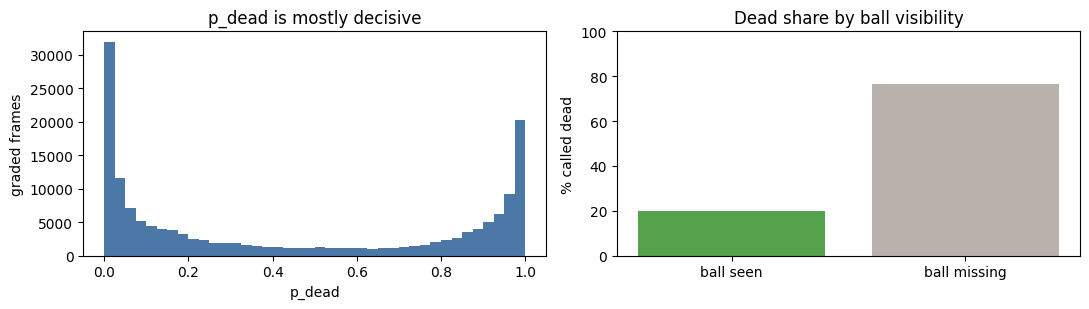

In [31]:
seen = ~np.isnan(ball_raw[:, 0])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(p_dead[scored], bins=40, color='#4c78a8')
ax[0].set(xlabel='p_dead', ylabel='graded frames', title='p_dead is mostly decisive')
groups = {'ball seen': scored & seen, 'ball missing': scored & ~seen}
ax[1].bar(list(groups), [100 * (p_dead[m] > 0.5).mean() for m in groups.values()], color=['#54a24b', '#bab0ac'])
ax[1].set(ylabel='% called dead', title='Dead share by ball visibility', ylim=(0, 100))
plt.tight_layout()

lengths = np.array([e - s for s, e in dead_ball.runs(dead)]) / 25
print('%d stoppages, median %.1f s, middle half %.1f-%.1f s' % (len(lengths), np.median(lengths),
                                                              *np.percentile(lengths, [25, 75])))

### Cross-check with Section 2

`p_dead` never reads the tags, so agreement with them is independent evidence: each set-piece window (`restart`) should contain a stoppage.

A window is about 30 s long and the stoppage inside it is often only a few seconds, so expect most of each window to be live. The check is whether *any* of it is dead.

In [32]:
windows = dead_ball.runs((restart > 0) & scored)
print('%.0f%% of %d set-piece windows contain a stoppage' % (100 * np.mean([dead[s:e].any() for s, e in windows]),
                                                          len(windows)))
print('share of window frames called dead: %.0f%% (stoppages are short, windows are long)'
      % (100 * dead[scored & (restart > 0)].mean()))
print()
print('Section 4 inputs now ready, one row per frame:')
for name, arr in (('ball_xy', ball_xy), ('ball_conf', ball_conf), ('st_team', st_team),
                  ('restart_team', restart_team), ('p_dead', p_dead)):
    print('  %-13s %s' % (name, arr.shape))

96% of 50 set-piece windows contain a stoppage
share of window frames called dead: 33% (stoppages are short, windows are long)

Section 4 inputs now ready, one row per frame:
  ball_xy       (199319, 2)
  ball_conf     (199319,)
  st_team       (199319,)
  restart_team  (199319,)
  p_dead        (199319,)
